# Train — ResNet-18 (scratch)

Trains and evaluates ResNet-18 (scratch) from random initial weights (no ImageNet pretraining), with the tuned hyperparameters in `ARCH_HYPERPARAMS["resnet18_scratch"]`, then saves its results and weights for the results notebooks.

In [1]:
from wwtw_utils import *

Using device: cuda
Test set ID: Fisantekraal
Train-time augmentation: on
Classes found (4): ['Dysfunctional', 'Empty', 'Functional', 'Scum']


## Data loaders and class weights

In [2]:
cfg = ARCH_HYPERPARAMS["resnet18_scratch"]

# Batch sizes above MICRO_BATCH_CAP are reached with gradient accumulation.
micro_batch = min(cfg["batch_size"], MICRO_BATCH_CAP)
accum_steps = max(1, round(cfg["batch_size"] / micro_batch))
print(f"ResNet-18 (scratch): micro batch = {micro_batch}, accumulation steps = {accum_steps} "
      f"(effective batch size ≈ {micro_batch * accum_steps}, target = {cfg['batch_size']})")

train_ds_arch, val_ds_arch, test_ds_arch, train_loader_arch, val_loader_arch, test_loader_arch = \
    get_dataloaders(cfg["img_size"], micro_batch)

class_weights_arch = make_class_weights(train_ds_arch)

ResNet-18 (scratch): micro batch = 16, accumulation steps = 2 (effective batch size ≈ 32, target = 32)
Train: 1829 | Val: 446 | Test: 252


## Model

In [3]:
model = models.resnet18(weights=None)
in_f = model.fc.in_features
model.fc = build_classifier_head(in_f, cfg["hidden_layers"], cfg["neurons"], num_classes)

model = model.to(device)

criterion = nn.CrossEntropyLoss(weight=class_weights_arch)
optimizer = optim.Adam(
    model.parameters(),
    lr=cfg["lr"],
    betas=(cfg["beta1"], ADAM_BETA2),
    weight_decay=WEIGHT_DECAY,
)
scheduler = StepLR(optimizer, step_size=cfg["step_size"], gamma=0.1)

## Train

[ResNet-18 (scratch)] Gradient accumulation: 2 micro-batches per optimizer step.


[ResNet-18 (scratch)] Epoch   1/100 | LR: 6.83e-05 | train loss 1.0686 acc 0.501 | val loss 0.9829 acc 0.574 *


[ResNet-18 (scratch)] Epoch   2/100 | LR: 6.83e-05 | train loss 0.9406 acc 0.567 | val loss 0.7617 acc 0.677 *


[ResNet-18 (scratch)] Epoch   3/100 | LR: 6.83e-05 | train loss 0.8636 acc 0.601 | val loss 0.8558 acc 0.643


[ResNet-18 (scratch)] Epoch   4/100 | LR: 6.83e-05 | train loss 0.8317 acc 0.612 | val loss 0.8295 acc 0.650


...

[ResNet-18 (scratch)] Epoch  49/100 | LR: 6.83e-06 | train loss 0.1469 acc 0.926 | val loss 0.4304 acc 0.839


[ResNet-18 (scratch)] Epoch  50/100 | LR: 6.83e-06 | train loss 0.1626 acc 0.925 | val loss 0.4084 acc 0.848


[ResNet-18 (scratch)] Epoch  51/100 | LR: 6.83e-06 | train loss 0.1591 acc 0.925 | val loss 0.4203 acc 0.843


[ResNet-18 (scratch)] Epoch  52/100 | LR: 6.83e-06 | train loss 0.1596 acc 0.933 | val loss 0.4327 acc 0.848


[ResNet-18 (scratch)] Epoch  53/100 | LR: 6.83e-06 | train loss 0.1605 acc 0.928 | val loss 0.4189 acc 0.845

[ResNet-18 (scratch)] No val loss improvement for 10 epochs, stopping at epoch 53.

[ResNet-18 (scratch)] Restored best checkpoint (val loss = 0.3968)


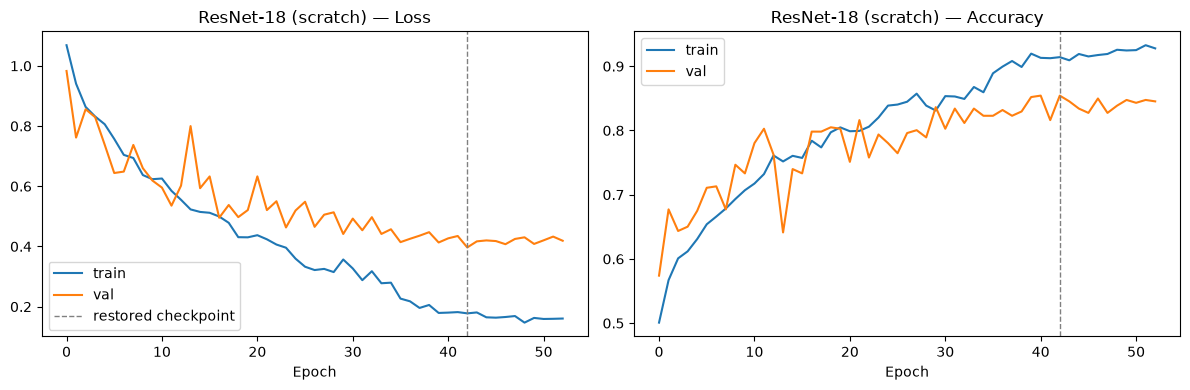

In [4]:
history = train_model(
    model, train_loader_arch, val_loader_arch, optimizer, scheduler,
    criterion, EPOCHS, EARLY_STOP_PATIENCE, "ResNet-18 (scratch)", is_inception=False,
    accum_steps=accum_steps,
)
plot_training_curves(history, "ResNet-18 (scratch)")

## Evaluate on the test set

[ResNet-18 (scratch)] Test accuracy: 0.730


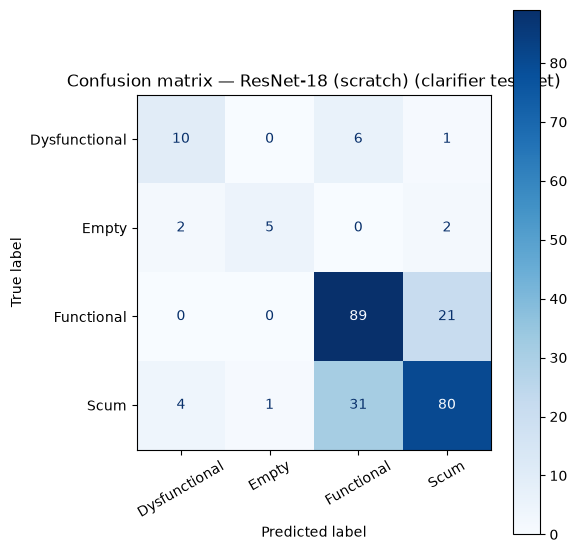

               precision    recall  f1-score   support

Dysfunctional      0.625     0.588     0.606        17
        Empty      0.833     0.556     0.667         9
   Functional      0.706     0.809     0.754       110
         Scum      0.769     0.690     0.727       116

     accuracy                          0.730       252
    macro avg      0.733     0.661     0.689       252
 weighted avg      0.734     0.730     0.729       252



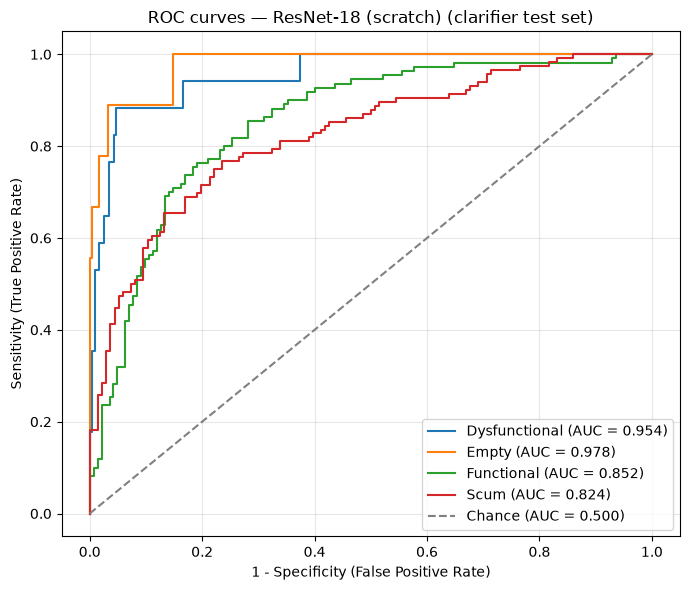

AUC (area under ROC curve) per class:
  Dysfunctional  : 0.954
  Empty          : 0.978
  Functional     : 0.852
  Scum           : 0.824

Mean AUC (over 4/4 classes with test examples): 0.902


(np.float64(0.7301587301587301),
 {'Dysfunctional': 0.9541927409261577,
  'Empty': 0.9775948788294467,
  'Functional': 0.8516005121638924,
  'Scum': 0.8237829614604463})

In [5]:
evaluate_and_record(
    model, test_loader_arch, "ResNet-18 (scratch)", history,
    img_size=cfg["img_size"], hidden_layers=cfg["hidden_layers"], neurons=cfg["neurons"],
    dev_loader=val_loader_arch,
)

## Save results and weights

In [6]:
save_result("ResNet-18 (scratch)", "resnet18_scratch")

Saved results to ../results/clarifier_aug/results_clarifier_resnet18_scratch_Fisantekraal.pkl
Saved model weights to ../models/pad/clarifier_aug/clarifier_resnet18_scratch_Fisantekraal.pt
